In [1]:
# Cell 1: Imports and Database Connection Setup
from dotenv import load_dotenv
import os
from sqlalchemy import create_engine
import pandas as pd

# Load environment variables from the root .env file
load_dotenv(dotenv_path='../.env')

# Initialize the SQLAlchemy engine for Supabase
engine = create_engine(os.getenv('SUPABASE_URL'))

In [2]:
# Load the primary datasets we want to inspect
orders_df = pd.read_sql('SELECT * FROM orders', engine)
order_items_df = pd.read_sql('SELECT * FROM order_items', engine)
products_df = pd.read_sql('SELECT * FROM products', engine)
payments_df = pd.read_sql('SELECT * FROM payments', engine)

In [3]:
# Cell 2: First look at the data
# Let's inspect the first 5 rows of our main tables
print("--- Orders Table Head ---")
print(orders_df.head())


--- Orders Table Head ---
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 

In [4]:

print("\n--- Order Items Table Head ---")
print(order_items_df.head())


--- Order Items Table Head ---
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-1

In [5]:
# Cell 3: Check columns, non-null counts, and datatypes
print("--- Orders Info ---")
orders_df.info()

print("\n--- Order Items Info ---")
order_items_df.info()

--- Orders Info ---
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB

--- Order Items Info ---
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-nul

In [6]:
# Cell 4: Check for missing values in each table
print("--- Missing Values in Orders ---")
print(orders_df.isnull().sum())

print("\n--- Missing Values in Order Items ---")
print(order_items_df.isnull().sum())

print("\n--- Missing Values in Products ---")
print(products_df.isnull().sum())

--- Missing Values in Orders ---
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

--- Missing Values in Order Items ---
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

--- Missing Values in Products ---
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [7]:
print("--- Duplicate Row Counts ---")
print(f"Orders duplicate rows: {orders_df.duplicated().sum()}")
print(f"Order Items duplicate rows: {order_items_df.duplicated().sum()}")
print(f"Products duplicate rows: {products_df.duplicated().sum()}")

--- Duplicate Row Counts ---
Orders duplicate rows: 0
Order Items duplicate rows: 0
Products duplicate rows: 0


In [8]:
# Cell 6: Generate statistical summary
print("--- Order Items Statistical Summary ---")
print(order_items_df.describe())

print("\n--- Payments Statistical Summary ---")
print(payments_df.describe())

--- Order Items Statistical Summary ---
       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000

--- Payments Statistical Summary ---
       payment_sequential  payment_installments  payment_value
count       103886.000000         103886.000000  103886.000000
mean             1.092679              2.853349     154.100380
std              0.706584              2.687051     217.494064
min              1.000000              0.000000       0.000000
25%              1.000000              1.000000      56.790000
50%              1.000000              1.000000     100.000000
75%              1.000

In [9]:
# Cell 7: Phase 2B - Cast date columns to true datetime types
# In orders_df
date_cols_orders = [
    'order_purchase_timestamp', 
    'order_approved_at', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in date_cols_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

# In order_items_df
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])

# Verify that the types have changed from 'object' to 'datetime64[ns]'
print("--- Verified Date Types in orders_df ---")
print(orders_df[date_cols_orders].dtypes)

--- Verified Date Types in orders_df ---
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [11]:
# Cell 8: Investigate rows with payment_installments == 0
zero_installments = payments_df[payments_df['payment_installments'] == 0]
print(f"Number of rows with 0 installments: {len(zero_installments)}")
print("\nSample of rows with 0 installments:")
zero_installments.head()

Number of rows with 0 installments: 2

Sample of rows with 0 installments:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79016,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [12]:
# Cell 9: Clean payments and products data

# 1. Investigate and fix payment installments
# Find if there are payments with 0 installments
zero_inst_count = (payments_df['payment_installments'] == 0).sum()
print(f"Rows with 0 installments before cleaning: {zero_inst_count}")

# We replace 0 installments with 1 (logical assumption: if paid, it took at least 1 payment)
payments_df.loc[payments_df['payment_installments'] == 0, 'payment_installments'] = 1
print(f"Rows with 0 installments after cleaning: {(payments_df['payment_installments'] == 0).sum()}")

# 2. Fill missing product categories with 'unknown'
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')

# 3. Fill missing physical dimensions with their median values (median is robust to outliers)
dim_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for col in dim_cols:
    median_val = products_df[col].median()
    products_df[col] = products_df[col].fillna(median_val)

print("\n--- Verified missing values in Products after cleaning ---")
print(products_df.isnull().sum())

Rows with 0 installments before cleaning: 2
Rows with 0 installments after cleaning: 0

--- Verified missing values in Products after cleaning ---
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                0
product_length_cm               0
product_height_cm               0
product_width_cm                0
dtype: int64


In [13]:
# Cell 10: Analyze and clean missing order dates

# Let's inspect the order status for rows where order_delivered_customer_date is null
print("Order status for missing delivery dates:")
print(orders_df[orders_df['order_delivered_customer_date'].isnull()]['order_status'].value_counts())

# Decision: Do not drop these rows! They are valid non-delivered orders.
# However, we will create a helper column for 'delivery_completed' (1 for delivered, 0 otherwise)
orders_df['delivery_completed'] = orders_df['order_delivered_customer_date'].notnull().astype(int)
print(f"\nDelivery completed flag counts:\n{orders_df['delivery_completed'].value_counts()}")

Order status for missing delivery dates:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Delivery completed flag counts:
delivery_completed
1    96476
0     2965
Name: count, dtype: int64


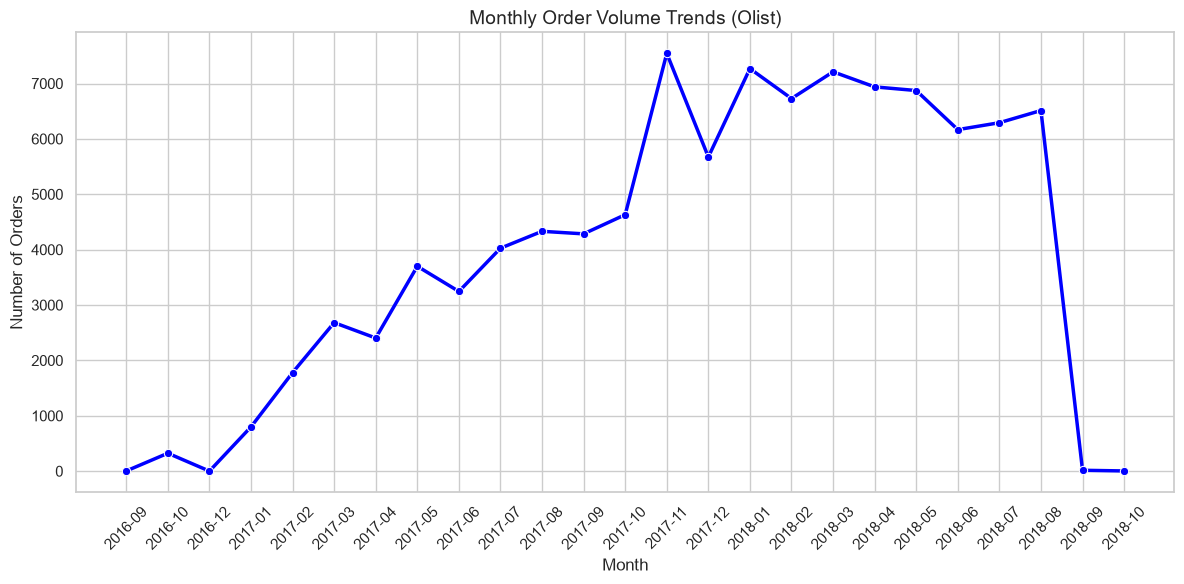

In [14]:
# Cell 11: Plot monthly order volume trends
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for Code With Harry style clean plots
sns.set_theme(style="whitegrid")

# Extract Year-Month for grouping
orders_df['year_month'] = orders_df['order_purchase_timestamp'].dt.to_period('M')

# Count orders per month
monthly_orders = orders_df.groupby('year_month').size()

# Convert Period index to timestamp strings for plotting
monthly_orders.index = monthly_orders.index.astype(str)

plt.figure(figsize=(12, 6))
sns.lineplot(x=monthly_orders.index, y=monthly_orders.values, marker="o", color="blue", linewidth=2.5)
plt.xticks(rotation=45)
plt.title("Monthly Order Volume Trends (Olist)", fontsize=14)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)
plt.tight_layout()
plt.show()

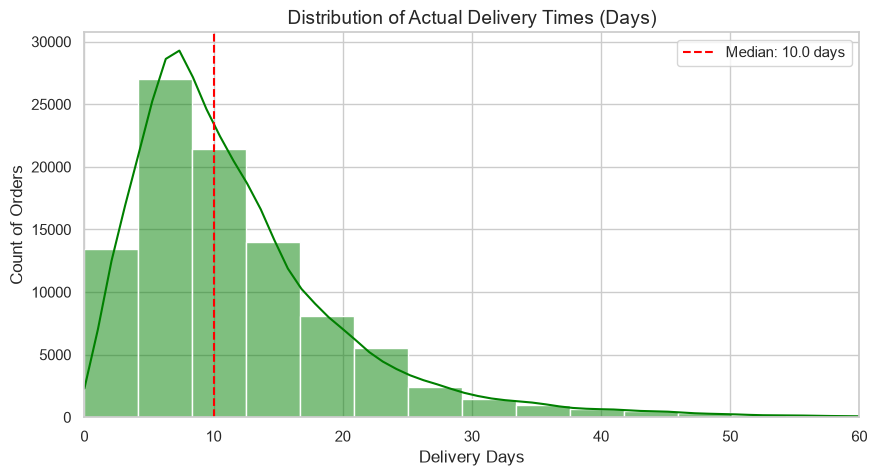

In [15]:
# Cell 12: Calculate and plot delivery delays

# Calculate delivery duration in days (delivered date - purchase date)
# Only run this on completed deliveries
delivered_orders = orders_df[orders_df['delivery_completed'] == 1].copy()
delivered_orders['actual_delivery_days'] = (delivered_orders['order_delivered_customer_date'] - delivered_orders['order_purchase_timestamp']).dt.days

# Calculate difference between estimated delivery and actual delivery
# Negative values mean the package arrived early (good!)
# Positive values mean the package arrived late (bad!)
delivered_orders['days_diff_estimated'] = (delivered_orders['order_delivered_customer_date'] - delivered_orders['order_estimated_delivery_date']).dt.days

plt.figure(figsize=(10, 5))
# Plot actual delivery times distribution
sns.histplot(delivered_orders['actual_delivery_days'], bins=50, kde=True, color="green")
plt.axvline(delivered_orders['actual_delivery_days'].median(), color='red', linestyle='--', label=f"Median: {delivered_orders['actual_delivery_days'].median():.1f} days")
plt.title("Distribution of Actual Delivery Times (Days)", fontsize=14)
plt.xlabel("Delivery Days", fontsize=12)
plt.ylabel("Count of Orders", fontsize=12)
plt.legend()
plt.xlim(0, 60) # Limit x-axis to zoom in past extreme outliers
plt.show()